# Nashville City Cemetery, 1846–1979: cleaning and reading the cause-of-death ledger

**Juan Zavala** · AI for Analytics · built with Claude as a pair programmer

The city's interment ledger has 19,745 entries for burials in the Nashville City Cemetery from 1846 to 1979, written by hand by cemetery clerks. Once 75 duplicate entries are removed, that is 19,670 burials. This notebook answers the nine questions in the assignment. The assignment is also a test of where an AI assistant saves time and where it needs a human to check it, so each answer shows its own checks.

**Work in progress:** questions 1–1 are done so far.

**Labels used below**

| Label | Meaning |
|---|---|
| **Prompt** | What the assignment asks, as it was given to Claude |
| **[CLAUDE]** | Code or an answer written by Claude |
| **[CHECK]** | A verification. Every claim marked "asserted" has an `assert`, so a re-run fails loudly if a number moves |
| **[REVIEW]** | A judgment call, or a place where the AI needed human oversight |

Every number in the text was copied from this notebook's executed output (`results/facts.json`). The notebook needs only pandas, numpy and matplotlib, and was run under Python 3.9 (pandas 2.3.3) and Python 3.10.

In [1]:
import difflib, hashlib, json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

import cause_of_death_rules as rules

DATA = Path('data/nashville_city_cemetery_interments_1846_1979.csv')
RESULTS, IMAGES = Path('results'), Path('images')
RESULTS.mkdir(exist_ok=True)
IMAGES.mkdir(exist_ok=True)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 70)

FACTS, TEXT = {}, {}          # every number quoted in the prose; saved to results/facts.json


def fact(key, value, text=None):
    """Record a number used in the prose (raw value + the exact text shown)."""
    FACTS[key] = value
    TEXT[key] = text if text is not None else (f'{value:,}' if isinstance(value, (int, np.integer)) else str(value))
    return value


def pct(x, d=1):
    return f'{100 * x:.{d}f}%'


def ranked(values):
    """value_counts with a fixed order for ties (count high to low, then name), so every environment ranks alike."""
    return values.value_counts().sort_index().sort_values(ascending=False, kind='stable')


# Chart style: the dataviz reference palette (light mode)
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE, AQUA, LIGHT_GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#c9c7bf'
AGE_ORDER = ['child', 'minors', 'young adults', 'middle aged', 'older adults', 'unknown']
AGE_COLORS = dict(zip(AGE_ORDER, ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281', '#c9c7bf']))
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'text.color': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'legend.frameon': False,
})


def save(fig, name):
    """Write the chart to images/ (the notebook also shows it inline below the cell)."""
    fig.savefig(IMAGES / name, dpi=150, bbox_inches='tight')


def age_group(age):
    """Question 6 bins on whole years: <=5 child, 6-17 minors, 18-30 young adults, 31-50 middle aged, >50 older adults, blank unknown."""
    a = np.floor(pd.to_numeric(age, errors='coerce'))
    out = np.select([a.isna(), a <= 5, a <= 17, a <= 30, a <= 50],
                    ['unknown', 'child', 'minors', 'young adults', 'middle aged'], 'older adults')
    return pd.Series(out, index=age.index)


def decade_label(year):
    """Question 5 format: 1846 -> "1840's"; blank year -> "unknown"."""
    y = pd.to_numeric(year, errors='coerce')
    lab = (y // 10 * 10).astype('Int64').astype(str) + "'s"
    return pd.Series(np.where(y.isna(), 'unknown', lab), index=year.index)

## Step 0. Load the ledger and check it before trusting it

The file is read as text (`dtype=str, keep_default_na=False`), so every code and blank comes through exactly as the clerks wrote it. Year and age are converted to numbers in helper columns, and the original columns stay untouched.

In [2]:
md5 = hashlib.md5(DATA.read_bytes()).hexdigest()
raw = pd.read_csv(DATA, dtype=str, keep_default_na=False)
assert md5 == '1fc59dc752d8c1ec10c0cff5aec09079', 'the data file is not the one this notebook was written for'

year_raw = pd.to_numeric(raw['Burial Year'], errors='coerce')
age_raw = pd.to_numeric(raw['Age'], errors='coerce')
fact('n_raw', len(raw))
fact('n_cols', raw.shape[1])
fact('n_spell_raw', int(raw['Cause of Death/Burial'].nunique()))
profile = pd.Series({
    'rows': len(raw),
    'columns': raw.shape[1],
    'burial years': f'{int(year_raw.min())}–{int(year_raw.max())}',
    'rows with no year': int(year_raw.isna().sum()),
    'rows with no age': f"{int(age_raw.isna().sum()):,} ({pct(age_raw.isna().mean())})",
    'ages of 100 or more': int((age_raw >= 100).sum()),
    'distinct cause spellings': raw['Cause of Death/Burial'].nunique(),
    'blank cause': int((raw['Cause of Death/Burial'].str.strip() == '').sum()),
    'Sex codes': raw['Sex'].value_counts().head(4).to_dict(),
    'Race codes': raw['Race'].value_counts().head(4).to_dict(),
}, name='value')
profile.to_frame()

,value
rows,19745
columns,14
burial years,1846–1979
rows with no year,2
rows with no age,"8,674 (43.9%)"
ages of 100 or more,39
distinct cause spellings,2210
blank cause,315
Sex codes,"{'M': 10108, 'F': 9372, '': 238, 'N': 7}"
Race codes,"{'W': 12887, 'B': 6735, 'D': 69, '': 47}"


### Duplicate ledger entries

The ledger comes in three sets of volumes. `4-1846`…`4-1860` and `5-1860`…`5-1881` are yearly books. The `6A`…`6Z` volumes are later lettered books, and they start in 1879. So for 1879–1881, some burials were written in both a yearly book and a lettered book. The cell below removes a lettered-book row when a yearly book already has the same named person in the same year and month.

Placeholder names such as "Infant" or "Unknown" are never removed, because two infants buried on the same day can be two different burials.

In [3]:
PLACEHOLDER = r'\b(?:inf\w*|inft|unknown|child|still|babe|baby|stranger|foundling|son of|daughter of|dau|boy|girl|man|woman)\b'
named = ~raw['Name'].str.lower().str.contains(PLACEHOLDER, regex=True) & raw['Name'].str.strip().ne('')
book = pd.Series(np.where(raw['Volume'].str.startswith('6'), 'lettered', 'yearly'), index=raw.index)

# (a) rows identical in every column except Volume: keep the yearly-book copy
cols_but_volume = [c for c in raw.columns if c != 'Volume']
srt = raw.assign(_lettered=(book == 'lettered').astype(int)).sort_values('_lettered', kind='stable')
same_entry = pd.Series(False, index=raw.index)
same_entry.loc[srt.index[srt.duplicated(subset=cols_but_volume, keep='first')]] = True
same_entry &= named

# (b) lettered-book copies of 1879-1881 burials already in a yearly book (same name, year and month;
#     day, age or spelling may differ by a typo)
key = raw['Name'].str.lower().str.replace(r'[^a-z]', '', regex=True) + '|' + raw['Burial Year'] + '|' + raw['Burial Month']
in_yearly = set(key[(book == 'yearly') & named])
repeat = named & (book == 'lettered') & key.isin(in_yearly) & year_raw.between(1879, 1881)

drop = same_entry | repeat
removed = raw[drop].assign(reason=np.where(same_entry[drop], 'identical except Volume', 'lettered-book copy of a 1879-1881 burial'))
removed.to_csv(RESULTS / 'duplicates_removed.csv', index_label='row')

df = raw[~drop].copy()
df['_year'] = pd.to_numeric(df['Burial Year'], errors='coerce')
df['_age'] = pd.to_numeric(df['Age'], errors='coerce')

fact('n_dup', int(drop.sum()))
fact('n_dup_identical', int(same_entry.sum()))
fact('n_clean', len(df))
assert removed['Volume'].str.startswith('6').all(), 'every removed copy should be from a lettered book'
assert year_raw[drop].between(1879, 1881).all()
print(f"removed {drop.sum()} duplicate rows ({same_entry.sum()} identical except Volume); {len(df):,} burials remain")
removed[['Volume', 'Name', 'Burial Month', 'Burial Day', 'Burial Year', 'Age', 'Cause of Death/Burial', 'reason']].head(6)

removed 75 duplicate rows (32 identical except Volume); 19,670 burials remain


,Volume,Name,Burial Month,Burial Day,Burial Year,Age,Cause of Death/Burial,reason
2170,6B,"Brown, M. G.",Apr,6,1881,18,Dropsey,lettered-book copy of a 1879-1881 burial
2172,6D,"Douglas, H.",Apr,8,1881,70,Heart Clab,lettered-book copy of a 1879-1881 burial
2175,6F,"Foster, Richard",Apr,12,1881,,Measles Compl,lettered-book copy of a 1879-1881 burial
2177,6H,"Hooper, A. J.",Apr,14,1881,81,Pneumonia,lettered-book copy of a 1879-1881 burial
2185,6K,"Kidwell, William",Apr,29,1881,26,Suicide,identical except Volume
2207,6C,"Crawford, A.",Feb,2,1881,66,Paralysis,identical except Volume


**[CHECK] Duplicates (asserted).** 75 rows are removed. All of them are lettered-book copies of 1879–1881 burials, and 32 of them are identical to the yearly-book row in every column except `Volume`. 19,670 burials remain, and every question below uses this de-duplicated table. The removed rows are saved in `results/duplicates_removed.csv`.

**[REVIEW] A famous entry is a reminder that the ledger is a clerk's record, not a fact sheet.** The row below is former President James K. Polk.

In [4]:
polk = raw[raw['Name'].str.contains('Ex president Polk', case=False)]
assert len(polk) == 1
fact('polk_age', int(polk['Age'].iloc[0]))
fact('polk_cause', polk['Cause of Death/Burial'].iloc[0])
polk[['Volume', 'Name', 'Burial Month', 'Burial Day', 'Burial Year', 'Age', 'Cause of Death/Burial', 'Remarks']]

,Volume,Name,Burial Month,Burial Day,Burial Year,Age,Cause of Death/Burial,Remarks
18256,4-1849,"Ex president Polk, J.K.",Jun,16,1849,64,Complicated,brick work


The ledger buries "Ex president Polk, J.K." on June 16, 1849, at age **64**, cause "**Complicated**". Polk was born in November 1795 and died in Nashville on June 15, 1849. That makes him 53, and most accounts attribute his death to cholera. (These dates come from Claude's general knowledge and were not checked against a source in this notebook, because this session had no web access. Juan should verify them before citing.)

The lesson for everything below: ages and causes are useful for patterns across thousands of burials, but any single entry can be wrong.

## Question 1. Fix spellings and group causes into `Cause of Death Updated`

> **Prompt (from the assignment, as given to Claude):** Examine the Cause of Death column. Fix spelling errors and group causes that belong together (for example, liver cancer and lung cancer → cancer; heart disease and heart attack → heart disease). Do not group different diseases that only share a symptom, such as Scarlet Fever and Yellow Fever. Ask me for details where you're unsure. When you're done, add the result as a new column named "Cause of Death Updated".

**How bad is the column?** In the 19,670 burials it has 2,209 distinct spellings. These are the twelve most common spellings in the cholera family, which turns out to be three different diseases:

In [5]:
cause_raw = df['Cause of Death/Burial']
cholera_like = cause_raw[cause_raw.str.lower().str.contains(r'chol|colney|colrey|colry|corey|colre', regex=True)
                         & ~cause_raw.str.lower().str.contains('cholic|cholick', regex=True)]
cholera_like.value_counts().head(12).rename_axis('as written').to_frame('burials').T

as written,Cholrea,Cholera,Cholera Infantum,Cholera Morbus,Cholrea Morbus,Cholera Inphantum,Cholrea Infantum,Colney Inphantom,Cholrea infantum,Cholra Morbus,Said Cholera,cholrea
burials,667,575,75,17,10,6,4,4,4,3,3,2


**[REVIEW] Questions Claude asked before grouping, and the default it used.** The assignment invites Claude to ask for details. Juan wasn't available while this was built, so each question below records the answer Claude chose, the reason, and the evidence. **Juan should confirm or change these.** Each one is a single line in `cause_of_death_rules.py`.

| Claude's question | Default used | Why |
|---|---|---|
| Is "Cholrea" the same as "Cholera"? | Yes, it's a spelling | It's how the 1849–50 and 1873 entries spell it, in the same epidemic years |
| Do "Cholera Morbus" and "Cholera Infantum" belong with Cholera? | **No**: three separate labels | Cholera morbus was acute gastroenteritis, and cholera infantum was infant summer diarrhea. Neither is epidemic cholera |
| "Summer complaint"? | With **Cholera Infantum** | The two names were used for the same infant summer diarrhea. Evidence below: almost every case is an infant |
| "S. Feever" and "T. Feever"? | **Scarlet Fever** and **Typhoid Fever** | Decided from the data (below): "S." cases are young children, as scarlet fever is; "T." cases are young adults, as typhoid is |
| Consumption, phthisis, tuberculosis? | One label, **Tuberculosis (consumption)** | Same disease under old and new names |
| "Phthisic"? | Its own label | Used for asthma as well as tuberculosis |
| "Lung fever", "inflammation of the lungs", "typhoid pneumonia"? | **Pneumonia** | Period names for pneumonia |
| "Flux"? | **Dysentery (flux)**, kept apart from Diarrhea | Flux was the period word for dysentery |
| "Yellow janders" / "yellow jaundice"? | **Jaundice**, not Yellow Fever | Same word "yellow", different disease |
| "Hives", "bold hives"? | Its own label | In old death records hives is not the skin rash, and its meaning is uncertain |
| "Congestive chill / fever"? | Its own label | Often severe malaria, but not certain enough to merge |
| "Membranous croup"? | **Croup** (flagged) | Often laryngeal diphtheria, but recorded as croup |
| "Child bed", "child bed fever"? | **Childbirth (incl. childbed fever)** | Both are deaths of mothers around childbirth |
| "Dropsy of the brain"? | **Hydrocephalus** | The standard period name |
| Birthplaces, undertakers, "died in Louisville"? | **Unknown** | These are notes, not causes |
| Two causes in one entry ("Measles & hooping cough")? | The cause written **first** | A few rows |
| "Tresmus nas" (trismus nascentium) and "mania a potu"? | **Tetanus** and **Alcoholism** | Newborn tetanus, and delirium tremens |
| "Complication" / "Complicated"? | Its own vague label | 755 rows whose meaning isn't recorded |

**[CLAUDE] The rules live in `cause_of_death_rules.py`.** A normalizer, a spelling dictionary and an ordered list of `(category, pattern)` rules are kept as data, so anyone can read and change them. A value that no rule matches keeps its corrected spelling instead of being forced into a group.

In [6]:
uniq = (cause_raw.value_counts().rename_axis('as written').reset_index(name='burials')
        .sort_values(['burials', 'as written'], ascending=[False, True], kind='stable').reset_index(drop=True))
decided = uniq['as written'].map(rules.categorize)
uniq['cleaned text'] = uniq['as written'].map(rules.clean_text)
uniq['Cause of Death Updated'] = decided.str[0]
uniq['method'] = decided.str[1]
uniq.to_csv(RESULTS / 'cause_mapping.csv', index=False)

mapping = dict(zip(uniq['as written'], uniq['Cause of Death Updated']))
pos = df.columns.get_loc('Cause of Death/Burial') + 1
df.insert(pos, 'Cause of Death Updated', cause_raw.map(mapping))

by_rule = uniq.groupby('method')['burials'].sum()
fact('n_spell', int(cause_raw.nunique()))
CHOLERA_FAMILY = ['Cholera', 'Cholera Morbus', 'Cholera Infantum (summer complaint)']
fact('n_cholera_family_spellings', int(uniq.loc[uniq['Cause of Death Updated'].isin(CHOLERA_FAMILY), 'as written'].nunique()))
fact('n_updated', int(df['Cause of Death Updated'].nunique()))
fact('n_rule_labels', int(uniq.loc[uniq['method'] == 'rule', 'Cause of Death Updated'].nunique()))
fact('n_complications', int((df['Cause of Death Updated'] == 'Complications (unspecified)').sum()))
fact('pct_rule', float(by_rule['rule'] / by_rule.sum()), pct(by_rule['rule'] / by_rule.sum()))
fact('n_spelling_only_rows', int(by_rule.get('spelling only', 0)))
fact('n_spelling_only_values', int((uniq['method'] == 'spelling only').sum()))
print(f"{df['Cause of Death Updated'].nunique()} labels from {cause_raw.nunique():,} spellings;",
      f"{by_rule['rule']:,} of {by_rule.sum():,} rows decided by a rule")
df.loc[:, ['Cause of Death/Burial', 'Cause of Death Updated']].sample(8, random_state=7)

232 labels from 2,209 spellings; 19,524 of 19,670 rows decided by a rule


,Cause of Death/Burial,Cause of Death Updated
18248,Cholrea,Cholera
13467,Still Born,Stillborn
11664,Flux,Dysentery (flux)
18174,Cholrea,Cholera
13585,Typhoid Fever,Typhoid Fever
17285,Cholrea,Cholera
7863,Unknown,Unknown
10785,Teething,Teething


In [7]:
# [CHECK] the assignment's own examples, plus the traps (asserted)
def cat(text):
    return rules.categorize(text)[0]

must = {
    'Cancer': ['Liver Cancer', 'Lung Cancer', 'Cancer of Stomach', 'Cancer on Breast', 'Cansor of Womb'],
    'Heart Disease': ['Heart Disease', 'Heart Attack', 'Heart Failure', 'Dis of Hart', 'Affection of the Heart'],
    'Scarlet Fever': ['Scarlet Fever', 'Scarlot Fever', 'Scarlett Feever', 'S. Feever'],
    'Yellow Fever': ['Yellow Fever'],
    'Jaundice': ['Yallow Janders', 'Yellow Jaundice', 'Jondice'],
    'Cholera': ['Cholrea', 'Cholera', 'Cholra'],
    'Cholera Morbus': ['Cholera Morbus', 'Cholrea Morbus', 'Colremobus'],
    'Cholera Infantum (summer complaint)': ['Cholera Infantum', 'Colney Inphantom', 'Summer Complt'],
    'Smallpox': ['Small Pox', 'Smal Pox'],
    'Chicken Pox': ['Chicken Pox'],
    'Tuberculosis (consumption)': ['Consumption', 'Consumson', 'Phthisis', 'Tuberculosis'],
    'Pneumonia': ['Pneumonia', 'Lung Fever', 'Infl. of Lungs', 'Typhoid Pneumonia', 'Numonia'],
    'Stillborn': ['Still Born', 'Stil Born', 'Stillborn', 'Still Bornd'],
}
for want, examples in must.items():
    for e in examples:
        assert cat(e) == want, (e, cat(e), want)
members = uniq.groupby('Cause of Death Updated')['cleaned text'].apply(lambda s: ' | '.join(s))
for label, text in members.items():
    assert not ('scarlet fever' in text and 'yellow fever' in text), label
    assert not ('chickenpox' in text and 'smallpox' in text), label
assert df['Cause of Death Updated'].notna().all() and (df['Cause of Death Updated'] != '').all()
assert df.columns[df.columns.get_loc('Cause of Death/Burial') + 1] == 'Cause of Death Updated'
print('all grouping checks pass')

all grouping checks pass


**[CHECK] Grouping (asserted).**
- The assignment's examples hold: liver cancer and lung cancer → Cancer, and heart disease and heart attack → Heart Disease.
- Scarlet Fever and Yellow Fever never share a label. Neither do Smallpox and Chicken Pox, or the three cholera terms.
- Every row has a value, and the new column sits immediately to the right of `Cause of Death/Burial`.

**[REVIEW] Two abbreviations were decided from the data, not guessed.**

In [8]:
norm = df['Cause of Death/Burial'].map(rules.normalize)
infant_name = df['Name'].str.lower().str.contains(r'\binf\w*|\binft|still|child|babe|baby', regex=True)
groups = {
    '"S. Feever"': norm.eq('s feever'),
    'scarlet fever, spelled out': df['Cause of Death Updated'].eq('Scarlet Fever') & ~norm.eq('s feever'),
    '"T. Feever"': norm.eq('t feever'),
    'typhoid fever, spelled out': df['Cause of Death Updated'].eq('Typhoid Fever') & ~norm.eq('t feever'),
    '"summer complaint" (all spellings)': df['Cause of Death/Burial'].map(rules.clean_text).eq('summer complaint'),
}
rows = []
for label, m in groups.items():
    s = df[m]
    rows.append({'cause as written': label, 'burials': len(s), 'years': f"{int(s['_year'].min())}–{int(s['_year'].max())}",
                 'median recorded age': s['_age'].median(), 'age <= 5 or infant name': pct(((s['_age'] <= 5) | infant_name[m]).mean(), 0)})
evidence = pd.DataFrame(rows).set_index('cause as written')
for key, row in [('s_fever_median_age', '"S. Feever"'), ('scarlet_median_age', 'scarlet fever, spelled out'),
                 ('t_fever_median_age', '"T. Feever"'), ('typhoid_median_age', 'typhoid fever, spelled out')]:
    v = float(evidence.loc[row, 'median recorded age'])
    fact(key, v, f'{v:g}')
fact('summer_infant_pct', evidence.loc['"summer complaint" (all spellings)', 'age <= 5 or infant name'])
assert evidence.loc['"S. Feever"', 'median recorded age'] <= 10 < evidence.loc['"T. Feever"', 'median recorded age']
evidence

,burials,years,median recorded age,age <= 5 or infant name
cause as written,,,,
"""S. Feever""",34,1846–1852,7.0,47%
"scarlet fever, spelled out",279,1847–1904,6.0,75%
"""T. Feever""",12,1846–1873,19.0,0%
"typhoid fever, spelled out",359,1852–1922,20.0,14%
"""summer complaint"" (all spellings)",202,1853–1896,1.0,99%


"S. Feever" has a median recorded age of 7, against 6 for scarlet fever spelled out. "T. Feever" has 19, against 20 for typhoid spelled out. Each abbreviation behaves like the disease it was mapped to. Summer complaint is an infant's illness: 99% of its burials are age 5 or under or have an infant name, which supports grouping it with cholera infantum.

**[REVIEW] Why fuzzy string matching was not allowed to choose the groups.** A common shortcut is to match each spelling to the closest category name by string similarity, as below. It fixes plain typos well. But it can't know medicine, so it confidently merges different diseases:

In [9]:
targets = ['cholera', 'cholera morbus', 'cholera infantum', 'scarlet fever', 'yellow fever', 'typhoid fever', 'bilious fever',
           'jaundice', 'smallpox', 'chicken pox', 'measles', 'consumption', 'teething', 'croup', 'diphtheria', 'brain fever',
           'dropsy', 'whooping cough', 'stillborn', 'old age', 'pneumonia', 'diarrhea', 'dysentery', 'heart disease', 'cancer']
tests = ['Cholrea', 'Measels', 'Stil Born', 'Teethin', 'Scarlot Fever',
         'Yallow Janders', 'Lung Fever', 'Child Bed Fever', 'Dropsey of Brain', 'Scrofula', 'Thrash']
rows = []
for t in tests:
    best = difflib.get_close_matches(t.lower(), targets, n=1, cutoff=0.0)[0]
    rows.append({'as written': t, 'closest by spelling': best,
                 'similarity': round(difflib.SequenceMatcher(None, t.lower(), best).ratio(), 2),
                 'rule-based answer': cat(t)})
fuzzy = pd.DataFrame(rows)
fuzzy['spelling match is right?'] = [r['rule-based answer'].lower().startswith(r['closest by spelling'][:6]) for _, r in fuzzy.iterrows()]
fact('fuzzy_wrong', int((~fuzzy['spelling match is right?']).sum()))
fuzzy

,as written,closest by spelling,similarity,rule-based answer,spelling match is right?
0,Cholrea,cholera,0.86,Cholera,True
1,Measels,measles,0.86,Measles,True
2,Stil Born,stillborn,0.89,Stillborn,True
3,Teethin,teething,0.93,Teething,True
4,Scarlot Fever,scarlet fever,0.92,Scarlet Fever,True
5,Yallow Janders,yellow fever,0.62,Jaundice,False
6,Lung Fever,bilious fever,0.70,Pneumonia,False
7,Child Bed Fever,typhoid fever,0.64,Childbirth (incl. childbed fever),False
8,Dropsey of Brain,dropsy,0.55,Hydrocephalus (dropsy of the brain),False
9,Scrofula,croup,0.62,Scrofula,False


Here is how the shortcut does. Plain typos are matched correctly: "Cholrea", "Measels" and "Stil Born". But 6 of these 11 entries end up under the wrong disease:
- "Yallow Janders" becomes *yellow fever*, though it is jaundice.
- "Lung Fever" becomes *bilious fever*, though it is pneumonia.
- "Child Bed Fever" becomes *typhoid fever*, though it is a childbirth death.
- "Dropsey of Brain" becomes plain *dropsy*, though it is hydrocephalus.
- "Scrofula" becomes *croup*, and "Thrash" (thrush) becomes *diphtheria*.

This is the oversight point of Question 1. String similarity proposed spelling fixes, and every grouping decision was written as an explicit rule and checked.

**Answer to Question 1.** The new column `Cause of Death Updated` turns 2,209 spellings into 232 labels. The three cholera labels alone absorb 81 spellings. 99.3% of rows are assigned by 100 explicit categories. The other 146 rows (135 rare or garbled entries such as "Piles" or "Locomotor Ataxia") keep their corrected text. The full raw → updated table is in `results/cause_mapping.csv`.

,distinct spellings
Cause of Death Updated,
Heart Disease,105
Bowel Inflammation / Disease,84
Lung Disease (other),72
Diarrhea,71
Tuberculosis (consumption),61
Pneumonia,59
"Kidney / Urinary Disease (Bright's disease, nephritis, gravel)",56
Cholera Infantum (summer complaint),52
Brain Fever / Inflammation,51


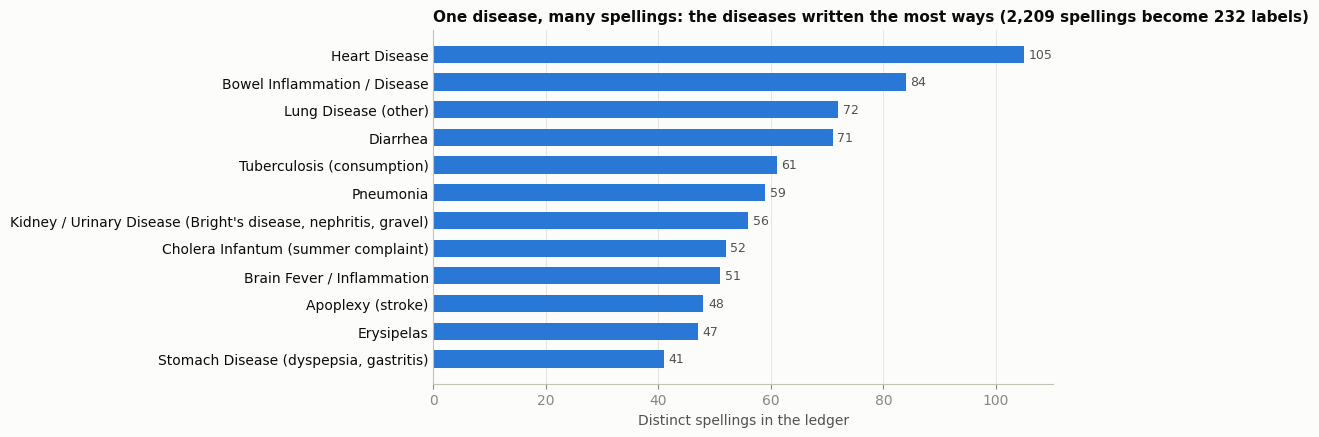

In [10]:
NOT_A_DISEASE = {rules.UNKNOWN, 'Accident', 'Gunshot', 'Homicide / Violence', 'Suicide', 'Drowning', 'Burns / Scalds', 'Poisoning / Overdose',
                 'Sudden Death', 'Suffocation (smothered, overlaid)', 'Exposure (heat or cold)', 'Wound (unspecified)', 'Killed in War'}
spellings = (uniq[(uniq['method'] == 'rule') & ~uniq['Cause of Death Updated'].isin(NOT_A_DISEASE)]
             .groupby('Cause of Death Updated')['as written'].nunique())
spellings = spellings.reset_index().sort_values(['as written', 'Cause of Death Updated'], ascending=[False, True]).set_index('Cause of Death Updated')['as written'].head(12)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(spellings.index[::-1], spellings.values[::-1], color=BLUE, height=0.62)
for y, v in enumerate(spellings.values[::-1]):
    ax.text(v + 0.8, y, f'{v}', va='center', color=INK2, fontsize=9)
ax.set_title(f"One disease, many spellings: the diseases written the most ways ({cause_raw.nunique():,} spellings become {df['Cause of Death Updated'].nunique()} labels)", fontsize=11)
ax.set_xlabel('Distinct spellings in the ledger')
ax.grid(axis='y', visible=False)
ax.tick_params(axis='y', length=0, labelcolor=INK)
save(fig, 'q1_spellings.png')
fact('most_spelled', spellings.index[0])
fact('most_spelled_n', int(spellings.iloc[0]))
spellings.to_frame('distinct spellings')

In [11]:
out = df.drop(columns=['_year', '_age'])
out.to_csv(RESULTS / 'cemetery_clean.csv', index=False)
new_cols = [c for c in ['Cause of Death Updated', 'decade', 'age group'] if c in out.columns]
for c in new_cols:
    left = out.columns[out.columns.get_loc(c) - 1]
    print(f"{c!r} sits right after {left!r}")
(RESULTS / 'facts.json').write_text(json.dumps({'facts': {k: (v if not isinstance(v, (np.integer, np.floating, np.bool_)) else v.item())
                                                         for k, v in FACTS.items()}, 'text': TEXT}, indent=1, ensure_ascii=False))
print(f'saved results/cemetery_clean.csv ({len(out):,} rows, {out.shape[1]} columns) and {len(FACTS)} facts')

'Cause of Death Updated' sits right after 'Cause of Death/Burial'
saved results/cemetery_clean.csv (19,670 rows, 15 columns) and 24 facts
